# 🏞️ Landscape Image Colorization with a Convolutional Autoencoder

Given only the **L (lightness)** channel of a landscape photo in the CIELAB color space, the network predicts the two missing color channels **a** (green↔red) and **b** (blue↔yellow).

This notebook is the full, original experiment log — including the two models that *didn't* work and why:

1. **Baseline autoencoder** (2,000 images, 100 epochs) → overfits.
2. **More data + Early Stopping** (5,000 images) → collapses into gray outputs.
3. **+ Batch Normalization** (5,000 images, 50 epochs) → realistic colors. ✅

> Runs on Google Colab with a T4 GPU. Downloading the dataset requires your own Kaggle API key (`kaggle.json`). **Never commit that file.**

## 1 · Get the dataset from Kaggle
[Landscape color and grayscale images](https://www.kaggle.com/datasets/theblackmamba31/landscape-image-colorization) — 7,129 color images (+ matching gray versions).

In [ ]:
#install Kaggle (since our needed data in Kaggle)
!pip install -q kaggle

In [ ]:
# Upload your kaggle.json file
from google.colab import files
import os
print("Please upload your kaggle.json file when asked.")
files.upload()

In [ ]:
# Move the key to the correct location so Kaggle library can find it
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json # Protect the key
print("Kaggle API Key successfully setup!")

Kaggle API Key successfully setup!


In [ ]:
# Download the dataset
# We use the dataset reference: "theblackmamba31/landscape-image-colorization"
!kaggle datasets download -d theblackmamba31/landscape-image-colorization

Dataset URL: https://www.kaggle.com/datasets/theblackmamba31/landscape-image-colorization
License(s): unknown
 79% 151M/192M [00:00<00:00, 1.57GB/s]
100% 192M/192M [00:00<00:00, 1.07GB/s]


In [ ]:
# Unzip the files
!unzip -q landscape-image-colorization.zip
print("Dataset downloaded and extracted!")

Dataset downloaded and extracted!


In [ ]:
import os
# Data Checking
base_dir = '/content/landscape Images'
if os.path.exists(base_dir):
    print("Found 'landscape Images' folder!")
    print("Contents:", os.listdir(base_dir))

    color_path = os.path.join(base_dir, 'color')
    gray_path = os.path.join(base_dir, 'gray')
    print(f"Color images found: {len(os.listdir(color_path))}")
    print(f"Gray images found: {len(os.listdir(gray_path))}")
else:
    print("Folder not found immediately. Let's look at what is in the current folder:")
    print(os.listdir('/content'))

Found 'landscape Images' folder!
Contents: ['color', 'gray']
Color images found: 7129
Gray images found: 7129


## 2 · Imports

In [ ]:
# Import needed libraries
import numpy as np
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from skimage.color import rgb2lab, lab2rgb, gray2rgb

## 3 · Preprocessing
The dataset's `gray/` folder is ignored on purpose: the L channel extracted from each color image is a mathematically exact grayscale version, so input and target are guaranteed to line up.

- resize to **128×128**
- RGB → **CIELAB**
- input `L / 100` → `[0, 1]`, target `ab / 128` → `≈[-1, 1]`

In [ ]:
# choosing 128x128 bc It's much faster for the model to learn than 256x256.
IMG_HEIGHT = 128
IMG_WIDTH = 128
# let's start with 2000 images this is enough to see results but won't take hours to load.
MAX_IMAGES = 2000
dataset_path = '/content/landscape Images/color'

In [ ]:
# Data Pre-Proccsesing (how to process an image)
def get_lab_data(path, max_count):
    X = [] # Input (Grayscale)
    Y = [] # Target (Colors)
    all_files = os.listdir(path)

    np.random.shuffle(all_files) # Shuffle so we get a random mix (mountains, forests, etc.)
    count = 0
    for filename in all_files:
        if count >= max_count:
            break
        try:
            # 1- Load and Resize
            img_path = os.path.join(path, filename)
            img = img_to_array(load_img(img_path, target_size=(IMG_HEIGHT, IMG_WIDTH)))

            # 2- Normalize RGB (0 to 1)
            img = img / 255.0

            # 3- Convert to Lab
            lab_image = rgb2lab(img)

            # 4- Split channels
            # L (Lightness) -> Input
            # We divide by 100 to normalize it to 0-1
            l_channel = lab_image[:,:,0] / 100.0

            # AB (Colors) -> Target
            # We divide by 128 to normalize it to -1 to 1
            ab_channels = lab_image[:,:,1:] / 128.0

            X.append(l_channel)
            Y.append(ab_channels)
            count += 1
            # Simple progress tracker
            if count % 500 == 0:
                print(f"Processed {count} images...")

        except Exception as e:
            pass

    # Convert to Numpy arrays
    X = np.array(X)
    Y = np.array(Y)
    X = X.reshape(X.shape[0], IMG_HEIGHT, IMG_WIDTH, 1) # Reshape X to add the channel dimension (128, 128, 1)
    return X, Y

In [ ]:
print("Starting data loading... please wait.")
X_train, Y_train = get_lab_data(dataset_path, MAX_IMAGES) # Run the function we just created

print("--------------------------------")
print("Data Loading Finished!")
print(f"Input Shape (Grayscale): {X_train.shape}")
print(f"Target Shape (Color AB): {Y_train.shape}")

Starting data loading... please wait.
Processed 500 images...
Processed 1000 images...
Processed 1500 images...
Processed 2000 images...
--------------------------------
Data Loading Finished!
Input Shape (Grayscale): (2000, 128, 128, 1)
Target Shape (Color AB): (2000, 128, 128, 2)


## 4 · Visualize a few samples

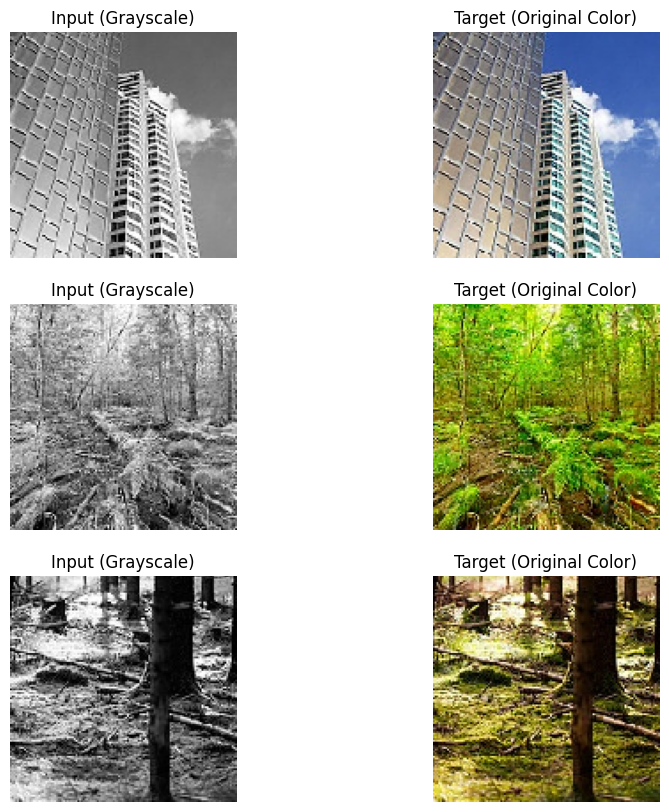

In [ ]:
# Function to view some samples for the data before training
def visualize_data(X_data, Y_data, samples=3):
    plt.figure(figsize=(10, 10))
    indices = np.random.randint(0, len(X_data), samples)

    for i, index in enumerate(indices):
        l_channel = X_data[index].reshape(128, 128)
        ab_channels = Y_data[index]

        curr_l = l_channel * 100
        curr_ab = ab_channels * 128

        lab_image = np.zeros((128, 128, 3))
        lab_image[:,:,0] = curr_l
        lab_image[:,:,1:] = curr_ab

        color_image = lab2rgb(lab_image)

        plt.subplot(samples, 2, 2*i + 1)
        plt.imshow(l_channel, cmap='gray')
        plt.title("Input (Grayscale)")
        plt.axis('off')

        plt.subplot(samples, 2, 2*i + 2)
        plt.imshow(color_image)
        plt.title("Target (Original Color)")
        plt.axis('off')

    plt.show()
visualize_data(X_train, Y_train)

## 5 · Model v1 — baseline convolutional autoencoder
- **Encoder:** 4 strided `Conv2D` layers (64 → 128 → 256 → 512 filters), 128×128 → 8×8
- **Decoder:** 4 strided `Conv2DTranspose` layers (256 → 128 → 64 → 64), 8×8 → 128×128
- **Output:** `Conv2D(2)` with `tanh` to match the `[-1, 1]` target range
- Loss: **MSE** on the ab channels, optimizer: **Adam**

In [ ]:
def build_autoencoder():
    # Input: 128x128 grayscale image (1 channel)
    input_img = layers.Input(shape=(128, 128, 1))

    # ENCODER (Compressing)
    # 128 -> 64
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same', strides=2)(input_img)
    # 64 -> 32
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same', strides=2)(x)
    # 32 -> 16
    x = layers.Conv2D(256, (3, 3), activation='relu', padding='same', strides=2)(x)
    # 16 -> 8 (Latent Space / Bottleneck)
    x = layers.Conv2D(512, (3, 3), activation='relu', padding='same', strides=2)(x)

    # DECODER (Decompressing)
    # 8 -> 16
    x = layers.Conv2DTranspose(256, (3, 3), activation='relu', padding='same', strides=2)(x)
    # 16 -> 32
    x = layers.Conv2DTranspose(128, (3, 3), activation='relu', padding='same', strides=2)(x)
    # 32 -> 64
    x = layers.Conv2DTranspose(64, (3, 3), activation='relu', padding='same', strides=2)(x)
    # 64 -> 128
    x = layers.Conv2DTranspose(64, (3, 3), activation='relu', padding='same', strides=2)(x)

    # OUTPUT LAYER
    decoded = layers.Conv2D(2, (3, 3), activation='tanh', padding='same')(x)
    # We output 2 channels (A and B color layers) and use 'tanh' because our target data is between -1 and 1

    autoencoder = models.Model(input_img, decoded)
    return autoencoder

In [ ]:
# Initialize the model
model = build_autoencoder()

In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['accuracy'])
# Adam is the standard optimizer
# MSE (Mean Squared Error) is perfect for pixel-by-pixel color comparison

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 256)    │     1,179,904 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 64)   │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 2)    │         1,154 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,136,642 (11.97 MB)

 Trainable params: 3,136,642 (11.97 MB)

 Non-trainable params: 0 (0.00 B)

## 6 · Train v1 — 2,000 images, 100 epochs, batch 32

In [ ]:
# Time for training
# Epochs: How many times the model sees the entire dataset.
# 100 is a good number for colorization.
# Since we have fewer images (2000), we need more epochs to learn well.
EPOCHS = 100
BATCH_SIZE = 32
print("Starting training...")
history = model.fit(
    X_train, Y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_split=0.1, # Use 10% of data to check if it's actually learning
    verbose=1 # Shows the progress bar
)
print("Training Finished!")

Starting training...
Epoch 1/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 21s 183ms/step - accuracy: 0.5108 - loss: 0.0123 - val_accuracy: 0.4961 - val_loss: 0.0121
Epoch 2/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.5112 - loss: 0.0116 - val_accuracy: 0.4961 - val_loss: 0.0121
Epoch 3/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.5315 - loss: 0.0118 - val_accuracy: 0.6063 - val_loss: 0.0112
Epoch 4/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.6204 - loss: 0.0109 - val_accuracy: 0.6485 - val_loss: 0.0108
Epoch 5/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.6582 - loss: 0.0102 - val_accuracy: 0.6705 - val_loss: 0.0100
Epoch 6/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.6703 - loss: 0.0096 - val_accuracy: 0.6720 - val_loss: 0.0098
Epoch 7/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.6704 - loss: 0.0094 - val_accuracy: 0.6693 - val_loss: 0.0092
Epoch 8/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.6645 - loss: 0.

## 7 · Prediction helper
Load → L channel → model predicts ab → recombine with the original L → back to RGB.

In [ ]:
# Function to see the visualization of our model prediction
def predict_and_colorize(img_path):
    # 1- Load the image (Resize to 128x128)
    img = img_to_array(load_img(img_path, target_size=(128, 128)))
    img = img / 255.0 # Normalize

    # 2- Convert to Lab
    lab_image = rgb2lab(img)

    # 3- Extract L Channel (Input)
    l_channel = lab_image[:,:,0]

    # 4- Prepare L for the model
    # Model expects (1, 128, 128, 1) normalized to 0-1
    input_l = l_channel / 100.0
    input_l = input_l.reshape(1, 128, 128, 1)

    # 5- PREDICTION TIME!
    # The model gives us the AB channels
    predicted_ab = model.predict(input_l)
    predicted_ab = predicted_ab.reshape(128, 128, 2)

    # 6- Un-normalize the prediction
    # We multiplied by 128 when training, so we multiply back now
    predicted_ab = predicted_ab * 128.0

    # 7- Combine L + Predicted AB
    result_lab = np.zeros((128, 128, 3))
    result_lab[:,:,0] = l_channel # Use original L
    result_lab[:,:,1:] = predicted_ab

    # 8- Convert to RGB
    result_rgb = lab2rgb(result_lab)
    return result_rgb, img

## 8 · Test v1 on new images

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


/tmp/ipython-input-2083111332.py:32: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 2 negative Z values that have been clipped to zero
  result_rgb = lab2rgb(result_lab)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


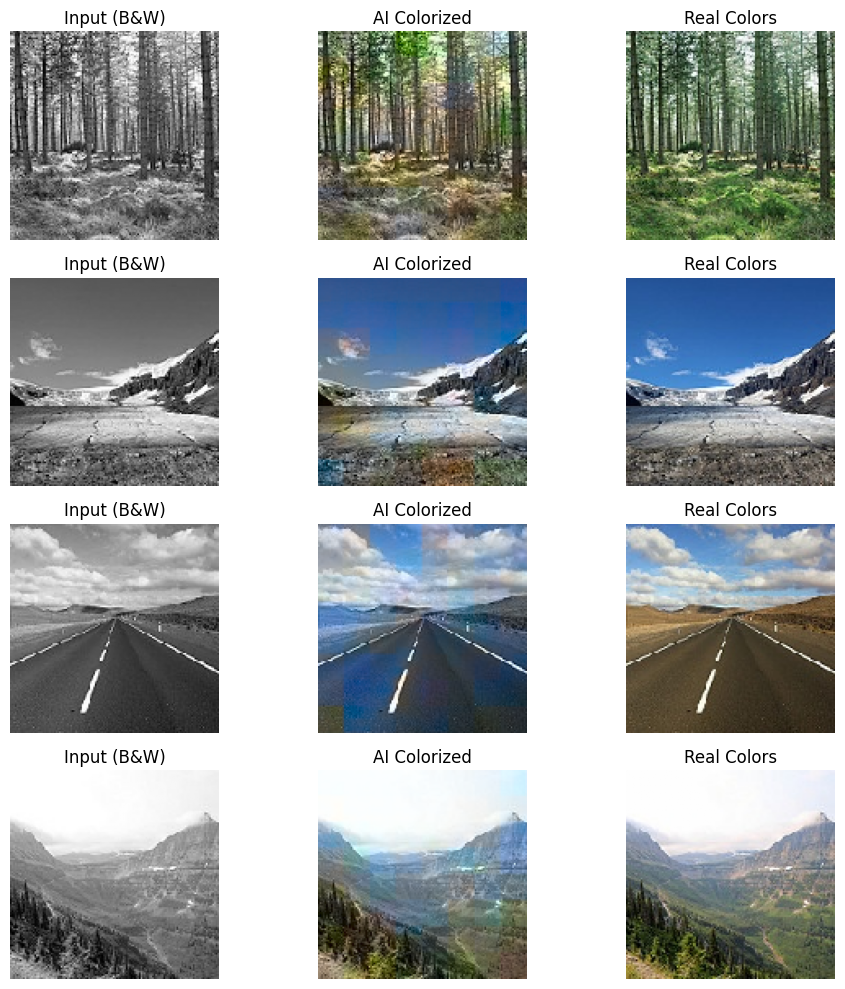

In [ ]:
# Let's pick some random files we haven't used yet
all_files = os.listdir(dataset_path)
# Picking specific indices past 2000 to ensure they are new
test_indices = [2005, 2500, 3050, 4100]

plt.figure(figsize=(10, 10))
for i, idx in enumerate(test_indices):
    filename = all_files[idx]
    filepath = os.path.join(dataset_path, filename)
    colorized_img, original_img = predict_and_colorize(filepath) # Run our prediction function
    gray_version = rgb2lab(original_img)[:,:,0] # Get the Grayscale version for display

    # PLOTTING
    # 1- Grayscale (Input)
    plt.subplot(4, 3, 3*i + 1)
    plt.imshow(gray_version, cmap='gray')
    plt.title("Input (B&W)")
    plt.axis('off')

    # 2- AI Colorized (Result)
    plt.subplot(4, 3, 3*i + 2)
    plt.imshow(colorized_img)
    plt.title("AI Colorized")
    plt.axis('off')

    # 3- Original (Ground Truth)
    plt.subplot(4, 3, 3*i + 3)
    plt.imshow(original_img)
    plt.title("Real Colors")
    plt.axis('off')
plt.tight_layout()
plt.show()

### Result: overfitting 😬
Training loss keeps dropping (≈0.0012) while validation loss stalls around ≈0.0095, and predictions show blotchy, patch-like colors. The model memorized the training images instead of learning general rules ("sky is blue, grass is green").

## 9 · Fix attempt #1 — more data + Early Stopping
- 2,000 → **5,000** training images
- `EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)`

In [ ]:
# The model faces an overfitting, now we're updating the model and do some regularization techniques to solve the problem
# Increasing data to 5000
MAX_IMAGES = 5000
IMG_HEIGHT = 128
IMG_WIDTH = 128
dataset_path = '/content/landscape Images/color'
print(f"Loading {MAX_IMAGES} images... This improves accuracy significantly.")

X_train, Y_train = get_lab_data(dataset_path, MAX_IMAGES)

print("--------------------------------")
print("New Data Loaded!")
print(f"Input Shape: {X_train.shape}")
print(f"Target Shape: {Y_train.shape}")

Loading 5000 images... This improves accuracy significantly.
Processed 500 images...
Processed 1000 images...
Processed 1500 images...
Processed 2000 images...
Processed 2500 images...
Processed 3000 images...
Processed 3500 images...
Processed 4000 images...
Processed 4500 images...
Processed 5000 images...
--------------------------------
New Data Loaded!
Input Shape: (5000, 128, 128, 1)
Target Shape: (5000, 128, 128, 2)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
# Reset the model (Clear previous memory)
model = build_autoencoder()
model.compile(optimizer='adam', loss='mse', metrics=['accuracy'])

In [ ]:
# Define the Safety Switch
# monitor='val_loss': the validation error
# patience=10: If the error doesn't improve for 10 epochs, STOP.
# restore_best_weights=True: Go back to the "best" moment before it got worse.
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)


In [ ]:
# Train on the larger dataset
print("Starting Training on 5000 images...")
history = model.fit(
    X_train, Y_train,
    batch_size=64, # Increased batch size slightly for speed
    epochs=100,
    validation_split=0.1,
    callbacks=[early_stop] # Add the safety switch here
)
print("Training Finished!")

Starting Training on 5000 images...
Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 35s 300ms/step - accuracy: 0.5123 - loss: 0.0125 - val_accuracy: 0.5066 - val_loss: 0.0125
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 129ms/step - accuracy: 0.5266 - loss: 0.0125 - val_accuracy: 0.5066 - val_loss: 0.0125
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 128ms/step - accuracy: 0.5216 - loss: 0.0123 - val_accuracy: 0.5066 - val_loss: 0.0125
Epoch 4/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 127ms/step - accuracy: 0.5128 - loss: 0.0119 - val_accuracy: 0.5066 - val_loss: 0.0125
Epoch 5/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 127ms/step - accuracy: 0.5222 - loss: 0.0123 - val_accuracy: 0.5066 - val_loss: 0.0124
Epoch 6/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 127ms/step - accuracy: 0.5124 - loss: 0.0123 - val_accuracy: 0.5066 - val_loss: 0.0125
Epoch 7/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 126ms/step - accuracy: 0.5185 - loss: 0.0121 - val_accuracy: 0.5066 - val_loss: 0.0125
Epoch 8/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 126ms/step - accur

## 10 · Test v2

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


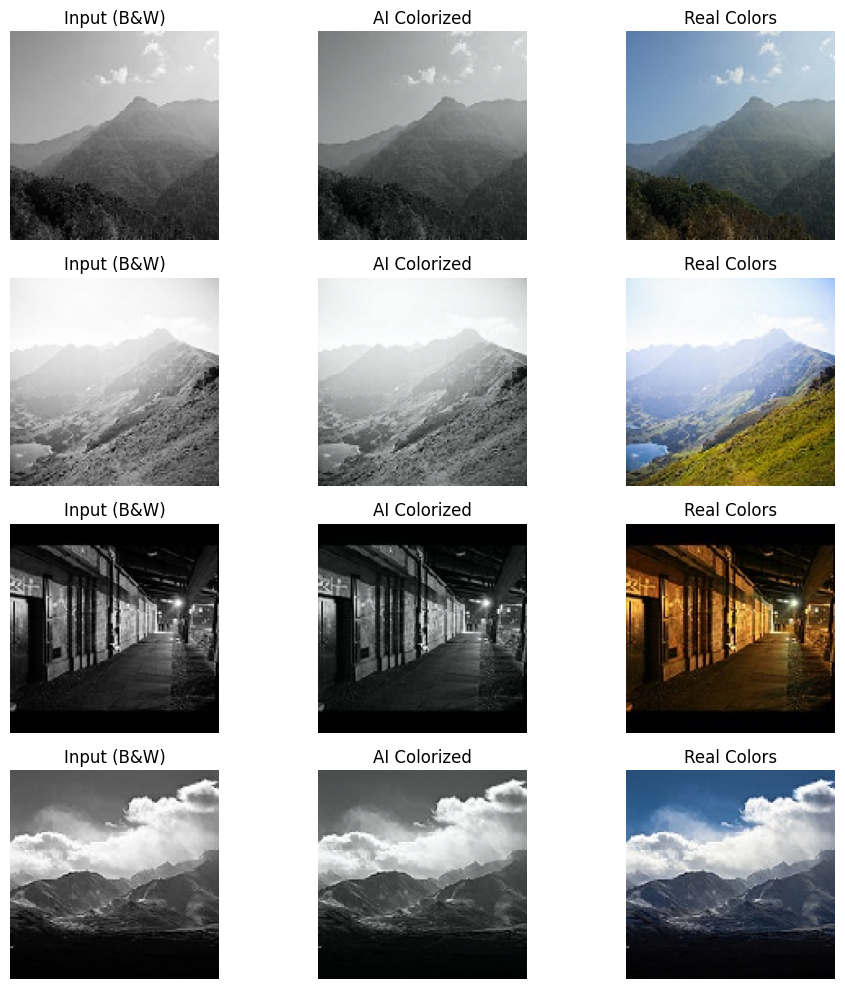

In [ ]:
# Let's pick random files from the dataset to test
all_files = os.listdir(dataset_path)
# Picking specific indices past 5000 to ensure they are NEW (Unseen)
test_indices = [5005, 5500, 6050, 6800]
plt.figure(figsize=(10, 10))
for i, idx in enumerate(test_indices):
    filename = all_files[idx]
    filepath = os.path.join(dataset_path, filename)

    # Run our prediction function
    colorized_img, original_img = predict_and_colorize(filepath)

    # Get the Grayscale version for display
    gray_version = rgb2lab(original_img)[:,:,0]

    # PLOTTING
    # Grayscale (Input)
    plt.subplot(4, 3, 3*i + 1)
    plt.imshow(gray_version, cmap='gray')
    plt.title("Input (B&W)")
    plt.axis('off')

    # AI Colorized (Result)
    plt.subplot(4, 3, 3*i + 2)
    plt.imshow(colorized_img)
    plt.title("AI Colorized")
    plt.axis('off')

    # Original (Ground Truth)
    plt.subplot(4, 3, 3*i + 3)
    plt.imshow(original_img)
    plt.title("Real Colors")
    plt.axis('off')
plt.tight_layout()
plt.show()

### Result: the "gray world" collapse 🩶
Training stopped at epoch 15 with the loss flat at ≈0.0125, and the outputs are basically grayscale.

With an MSE loss, predicting a wrong color (green instead of blue) is punished heavily, while predicting **≈0 for a and b (gray)** is only *a little* wrong everywhere. The network settled into that safe average, and Early Stopping ended training before it could escape.

## 11 · Fix attempt #2 — Batch Normalization
Same architecture, with `BatchNormalization()` after every convolution. Normalizing activations keeps the gradients healthy and the neurons active, so the model pushes past the gray phase. Early Stopping is removed and the model trains for a fixed 50 epochs.

In [ ]:
def build_strong_autoencoder():
    input_img = layers.Input(shape=(128, 128, 1))

    # ENCODER
    # We add BatchNormalization() after every Conv2D to fix the "Gray" problem

    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same', strides=2)(input_img)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(256, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(512, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    # DECODER
    x = layers.Conv2DTranspose(256, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2DTranspose(128, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2DTranspose(64, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2DTranspose(64, (3, 3), activation='relu', padding='same', strides=2)(x)
    x = layers.BatchNormalization()(x)

    # OUTPUT
    decoded = layers.Conv2D(2, (3, 3), activation='tanh', padding='same')(x)
    model = models.Model(input_img, decoded)
    return model

In [ ]:
# Initialize the stronger model
model = build_strong_autoencoder()
model.compile(optimizer='adam', loss='mse', metrics=['accuracy'])


In [ ]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 16, 16, 256)    │     1,179,904 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 128, 128, 64)   │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 128, 128, 2)    │         1,154 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,142,530 (11.99 MB)

 Trainable params: 3,139,586 (11.98 MB)

 Non-trainable params: 2,944 (11.50 KB)

## 12 · Train v3 — 5,000 images, 50 epochs, batch 64

In [ ]:
# No Early Stopping this time. We force the model to learn!
print("Starting Strong Training...")

history = model.fit(
    X_train, Y_train,
    batch_size=64,
    epochs=50,
    validation_split=0.1
)

Starting Strong Training...
Epoch 1/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step - accuracy: 0.5058 - loss: 0.0750 - val_accuracy: 0.4987 - val_loss: 0.0125
Epoch 2/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - accuracy: 0.5122 - loss: 0.0133 - val_accuracy: 0.4981 - val_loss: 0.0125
Epoch 3/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 148ms/step - accuracy: 0.5257 - loss: 0.0130 - val_accuracy: 0.4954 - val_loss: 0.0127
Epoch 4/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - accuracy: 0.5360 - loss: 0.0126 - val_accuracy: 0.4954 - val_loss: 0.0126
Epoch 5/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0.5538 - loss: 0.0119 - val_accuracy: 0.5125 - val_loss: 0.0133
Epoch 6/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.6472 - loss: 0.0107 - val_accuracy: 0.5105 - val_loss: 0.0131
Epoch 7/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.6708 - loss: 0.0102 - val_accuracy: 0.6381 - val_loss: 0.0115
Epoch 8/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.66

## 13 · Test v3 on the same images as v2

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 731ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


/tmp/ipython-input-2083111332.py:32: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 6 negative Z values that have been clipped to zero
  result_rgb = lab2rgb(result_lab)


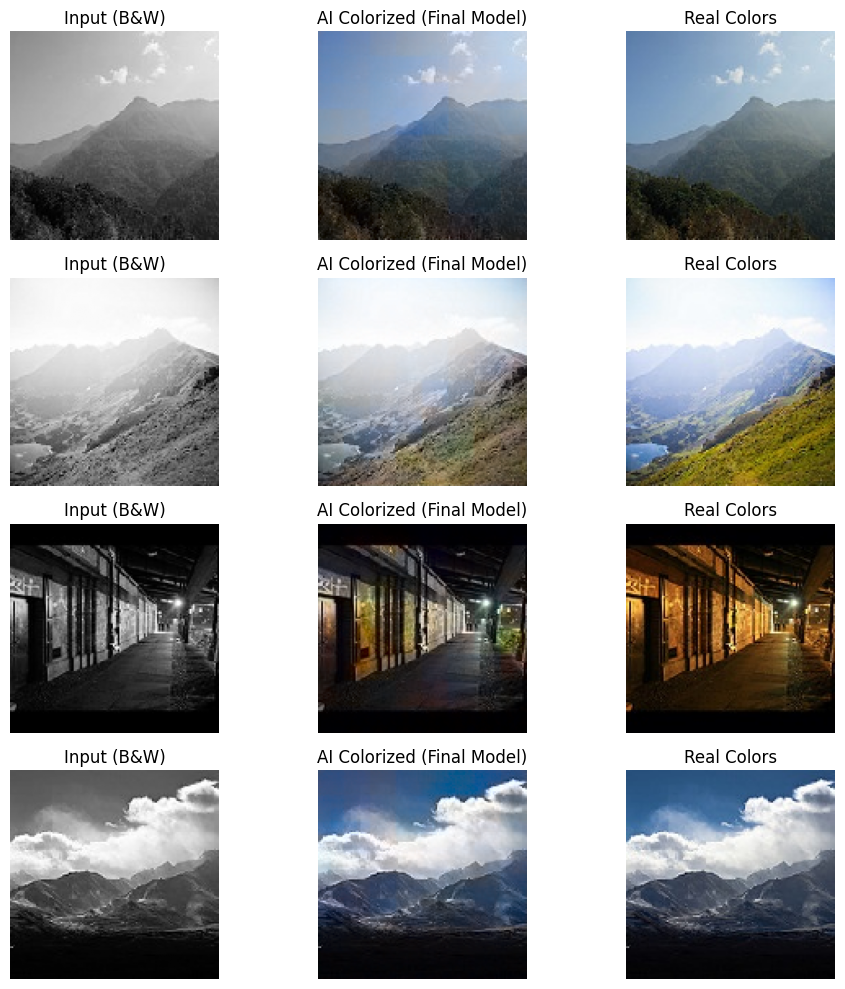

In [ ]:
all_files = os.listdir(dataset_path)
test_indices = [5005, 5500, 6050, 6800]
plt.figure(figsize=(10, 10))

for i, idx in enumerate(test_indices):
    filename = all_files[idx]
    filepath = os.path.join(dataset_path, filename)

    # Run prediction
    colorized_img, original_img = predict_and_colorize(filepath)
    gray_version = rgb2lab(original_img)[:,:,0]

    # PLOTTING
    plt.subplot(4, 3, 3*i + 1)
    plt.imshow(gray_version, cmap='gray')
    plt.title("Input (B&W)")
    plt.axis('off')

    plt.subplot(4, 3, 3*i + 2)
    plt.imshow(colorized_img)
    plt.title("AI Colorized (Final Model)")
    plt.axis('off')

    plt.subplot(4, 3, 3*i + 3)
    plt.imshow(original_img)
    plt.title("Real Colors")
    plt.axis('off')

plt.tight_layout()
plt.show()

## 14 · Final test on random images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


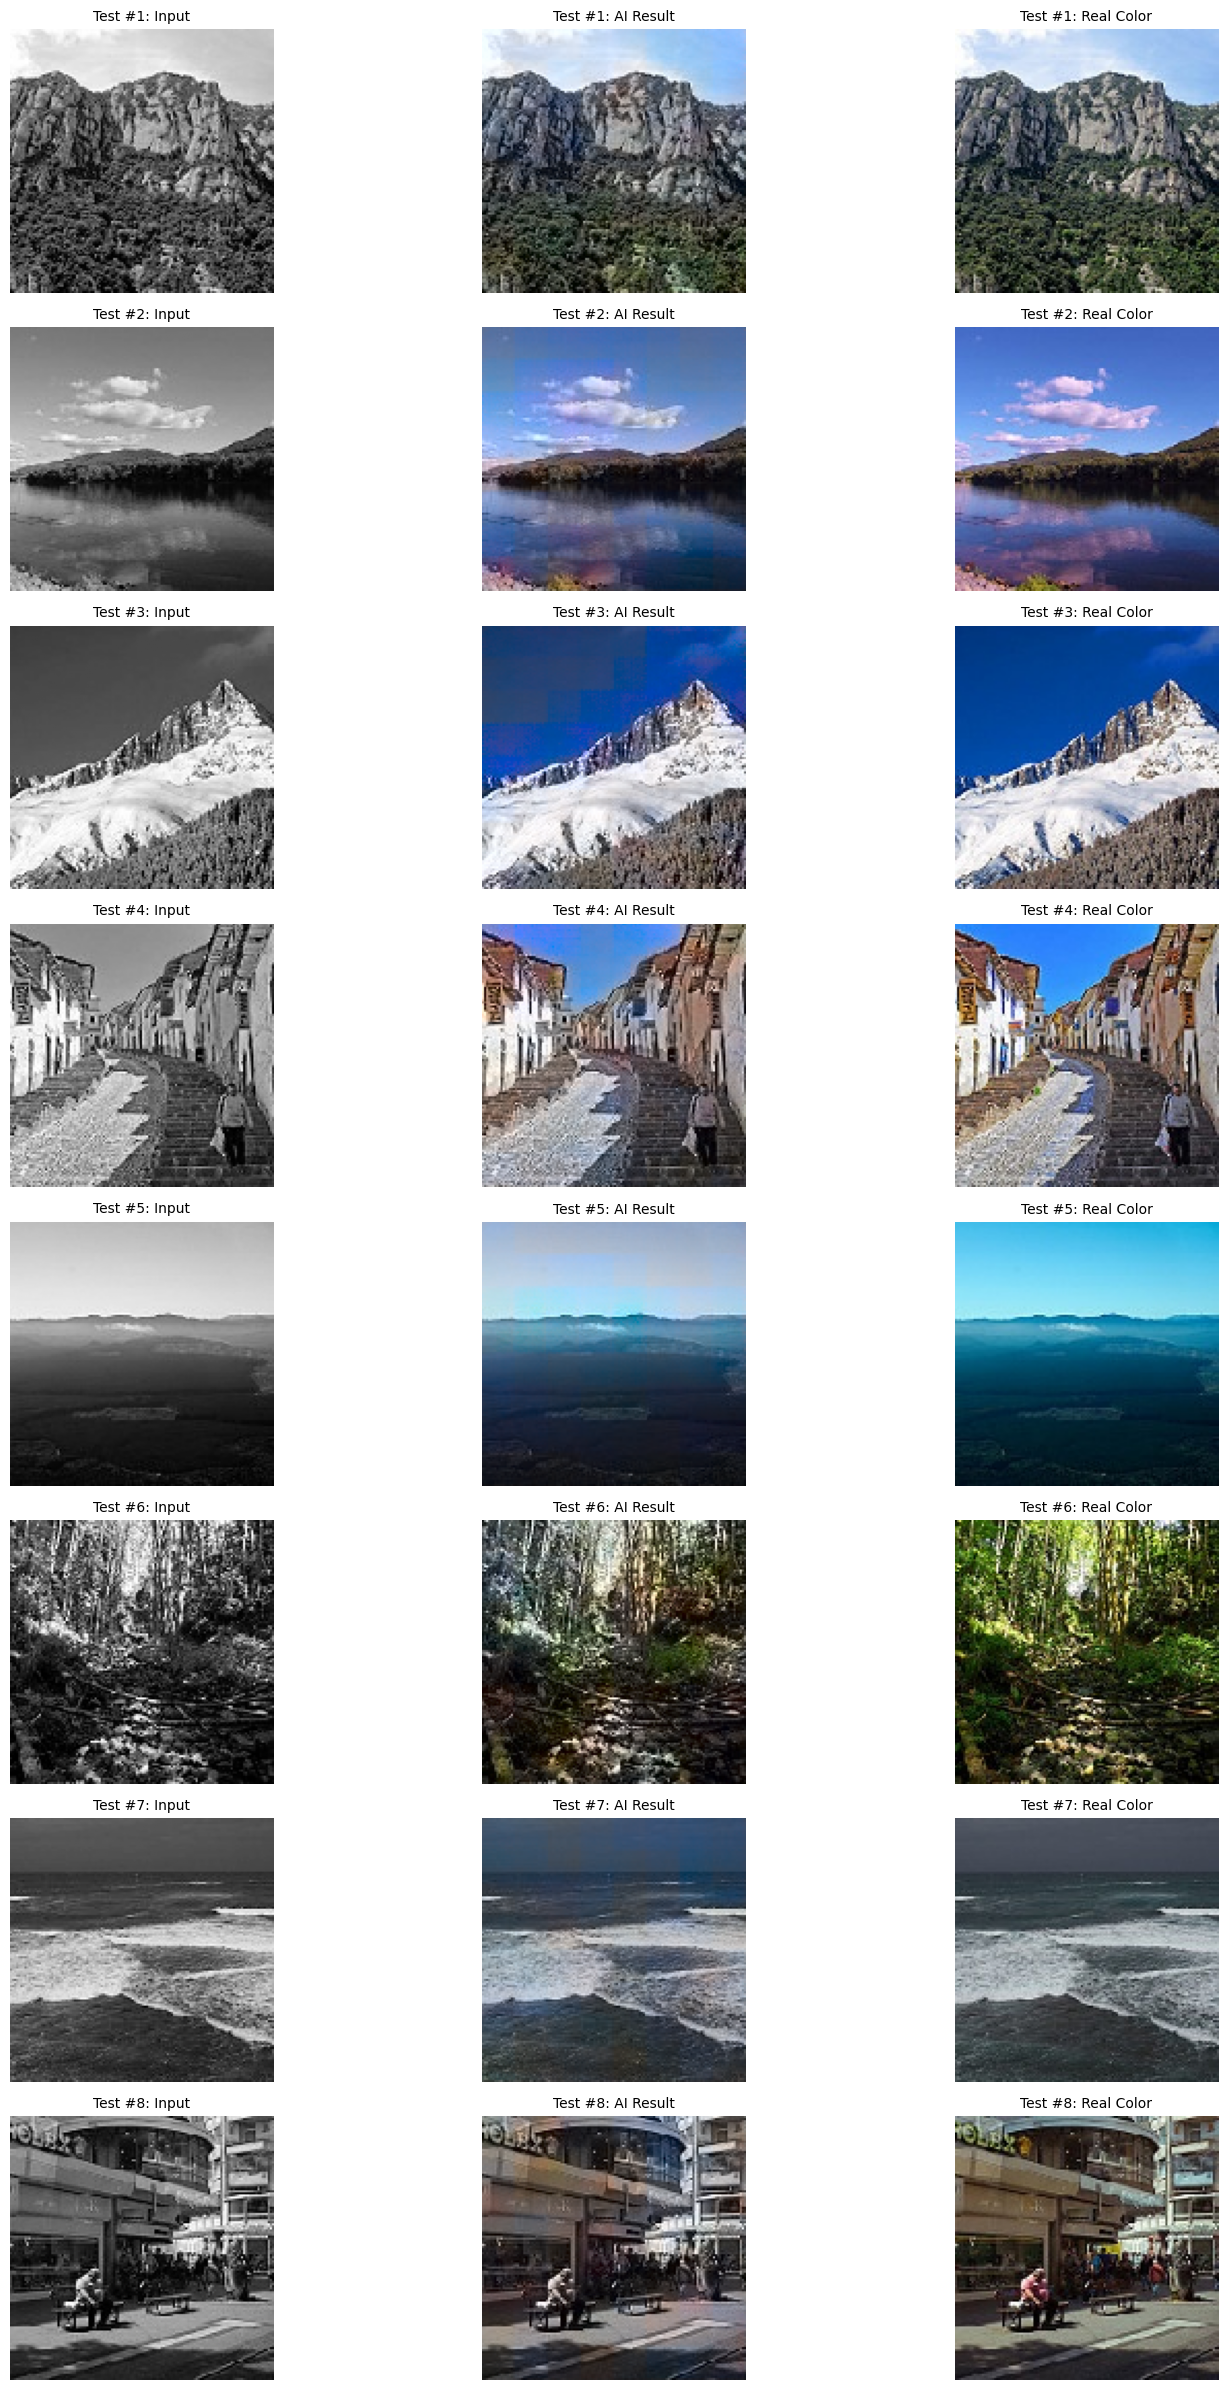

In [ ]:
# Pick 8 random numbers between 5000 and 7000 (The test zone)
# We use 'replace=False' so we don't pick the same image twice
random_indices = np.random.choice(np.arange(5000, len(all_files)), size=8, replace=False)
plt.figure(figsize=(16, 24)) # Making the figure big so we see details

for i, idx in enumerate(random_indices):
    filename = all_files[idx]
    filepath = os.path.join(dataset_path, filename)

    # Predict
    colorized_img, original_img = predict_and_colorize(filepath)
    gray_version = rgb2lab(original_img)[:,:,0]

    # Input
    plt.subplot(8, 3, 3*i + 1)
    plt.imshow(gray_version, cmap='gray')
    plt.title(f"Test #{i+1}: Input", fontsize=10)
    plt.axis('off')

    # AI Result
    plt.subplot(8, 3, 3*i + 2)
    plt.imshow(colorized_img)
    plt.title(f"Test #{i+1}: AI Result", fontsize=10)
    plt.axis('off')

    # Real Truth
    plt.subplot(8, 3, 3*i + 3)
    plt.imshow(original_img)
    plt.title(f"Test #{i+1}: Real Color", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

## 15 · Evaluation — PSNR & SSIM
Pixel "accuracy" is misleading for a regression task like colorization, so two image-restoration metrics are used instead:
- **PSNR** (Peak Signal-to-Noise Ratio) — 20–30 dB is a typical good range
- **SSIM** (Structural Similarity) — closer to 1.0 is better

In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
import numpy as np

def evaluate_model_metrics(dataset_path, num_samples=100):
    print(f"Calculating scores for {num_samples} images...")
    all_files = os.listdir(dataset_path)
    # Pick random images from the 'unseen' test area
    indices = np.random.choice(np.arange(5000, len(all_files)), size=num_samples, replace=False)

    psnr_scores = []
    ssim_scores = []

    for idx in indices:
        filepath = os.path.join(dataset_path, all_files[idx])

        # 1- Get Prediction and Ground Truth
        # We use our function but modify it slightly to return arrays, not plot
        img = img_to_array(load_img(filepath, target_size=(128, 128))) / 255.0
        lab_image = rgb2lab(img)
        l_channel = lab_image[:,:,0]
        input_l = l_channel / 100.0
        input_l = input_l.reshape(1, 128, 128, 1)
        pred_ab = model.predict(input_l, verbose=0)
        pred_ab = pred_ab.reshape(128, 128, 2) * 128.0

        # Construct the "Predicted" Image
        pred_lab = np.zeros((128, 128, 3))
        pred_lab[:,:,0] = l_channel
        pred_lab[:,:,1:] = pred_ab
        pred_rgb = lab2rgb(pred_lab)

        # Construct the "Real" Image
        real_rgb = img # Since we loaded it as RGB normalized 0-1

        # 2- Calculate Metrics
        # Data range is 0 to 1 (because we normalized)
        score_p = psnr(real_rgb, pred_rgb, data_range=1.0)

        # Win_size must be smaller than image side (128). 7 is standard.
        # We specify channel_axis=2 because our image is (128, 128, 3)
        score_s = ssim(real_rgb, pred_rgb, data_range=1.0, win_size=3, channel_axis=2)

        psnr_scores.append(score_p)
        ssim_scores.append(score_s)

    # 3- Average Results
    avg_psnr = np.mean(psnr_scores)
    avg_ssim = np.mean(ssim_scores)

    print("--------------------------------")
    print(f" Average PSNR: {avg_psnr:.2f} dB (Higher is better)")
    print(f" Average SSIM: {avg_ssim:.4f} (Closer to 1.0 is better)")
    print("--------------------------------")

evaluate_model_metrics('/content/landscape Images/color') # Run the evaluation

**Recorded result (100 images):** Average PSNR = **27.51 dB**, Average SSIM = **0.9521**

> ⚠️ **Note on the split:** `get_lab_data` shuffles its own copy of the file list, while the test cells index the *unshuffled* `os.listdir` result. That means the "unseen" indices ≥ 5000 are not guaranteed to be held out, so these scores are likely optimistic. The `src/` scripts in this repo fix this with a seeded train/test split saved to `split.json`.

## Conclusion
A plain convolutional autoencoder can learn plausible landscape colors (blue skies, green vegetation). Batch Normalization was the key change that moved the model out of the gray-output collapse. Remaining limitations — checkerboard artifacts from transposed convolutions, soft edges and desaturated colors — point to skip connections (U-Net), a perceptual or classification-based color loss, and data augmentation as next steps.